# WEEK 02:LAB 1A: Sampling, Aliasing and Quantization

NAME:JANETH DISMAS EDWARD

REG NO: 240242496198

STREAM 02: GROUP 03



### Pre-lab Preparation

#### **(a) Alias Frequency Calculation**

**Step 1: Identify the given frequencies and Nyquist limit**
* Input tone frequency: $F = 7\text{ kHz}$
* Sampling frequency: $f_s = 10\text{ kHz}$
* Nyquist limit:
$$\frac{f_s}{2} = \frac{10\text{ kHz}}{2} = 5\text{ kHz}$$

**Step 2: Check for aliasing**
* Compare $F$ with the Nyquist limit: $7\text{ kHz} > 5\text{ kHz}$
* Since the input frequency exceeds the Nyquist limit, aliasing occurs.

**Step 3: Find the integer multiplier ($k$)**
$$k = \text{round}\left(\frac{F}{f_s}\right)$$
$$k = \text{round}\left(\frac{7}{10}\right)$$
$$k = \text{round}(0.7) = 1$$

**Step 4: Calculate the alias frequency ($F_{\text{alias}}$)**
$$F_{\text{alias}} = |F - k f_s|$$
$$F_{\text{alias}} = |7\text{ kHz} - 1(10\text{ kHz})|$$
$$F_{\text{alias}} = |-3\text{ kHz}|$$
$$F_{\text{alias}} = \mathbf{3\text{ kHz}}$$

---

#### **(b) Quantization Step Size ($\Delta$) and Theoretical SQNR**

**Step 1: Identify the quantizer parameters**
* Number of bits: $B = 8$
* Peak amplitude ($X_m$): $1\text{ V}$ (from the $\pm 1\text{ V}$ bipolar range)

**Step 2: Calculate the quantization step size ($\Delta$)**
$$\Delta = \frac{2 X_m}{2^B}$$
$$\Delta = \frac{2(1\text{ V})}{2^8}$$
$$\Delta = \frac{2\text{ V}}{256}$$
$$\Delta = \mathbf{0.0078125\text{ V}} \text{ (or } \mathbf{7.81\text{ mV}}\text{)}$$

**Step 3: Calculate the theoretical SQNR**
$$\text{SQNR} \approx 6.02B + 1.76$$
$$\text{SQNR} \approx 6.02(8) + 1.76$$
$$\text{SQNR} \approx 48.16 + 1.76$$
$$\text{SQNR} \approx \mathbf{49.92\text{ dB}}$$



Task 2.1 — Aliasing of a Sinusoid

fs (Hz)    | Nyquist (Hz)   | k     | Formula |F - k*fs|   | Measured Alias (Hz)
---------------------------------------------------------------------------
10.0       | 5.0            | 1     | |7 - 1*10| = 3.0       | 3.0
12.0       | 6.0            | 1     | |7 - 1*12| = 5.0       | 5.0
14.0       | 7.0            | 0     | |7 - 0*14| = 7.0       | 7.0
20.0       | 10.0           | 0     | |7 - 0*20| = 7.0       | 7.0


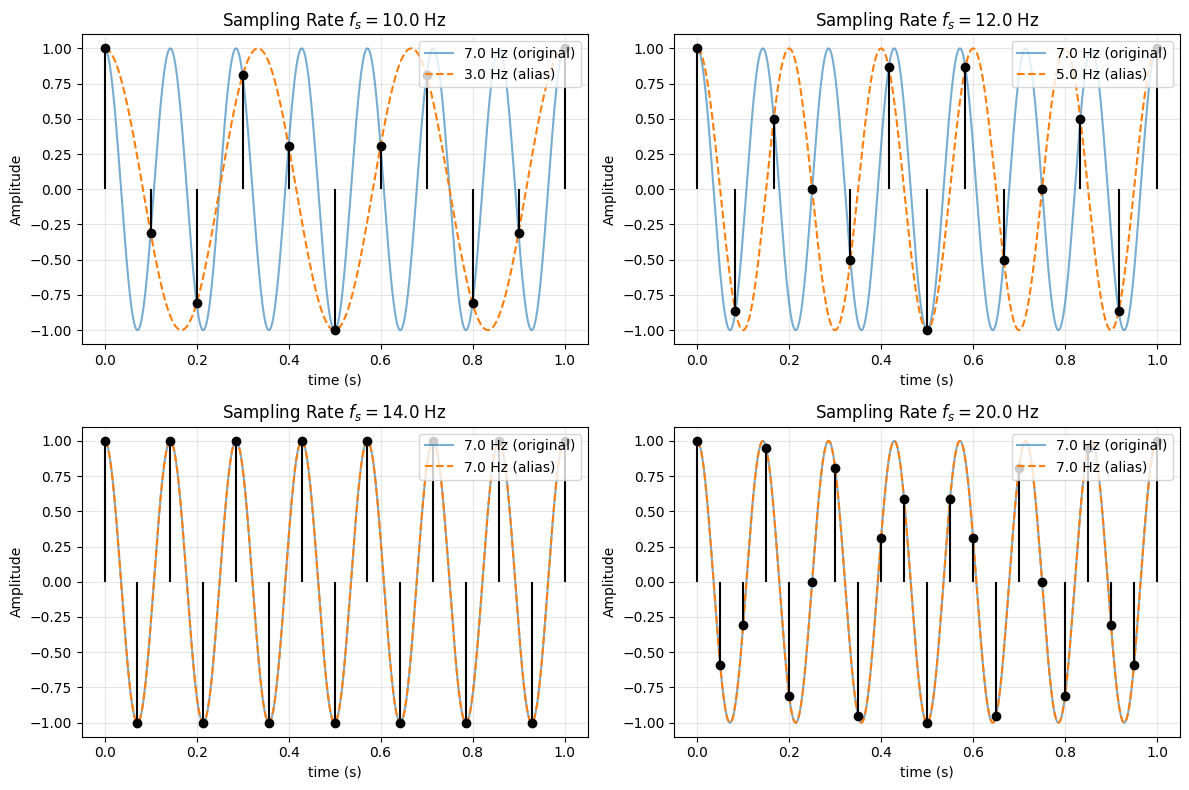

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

f0 = 7.0
fs_values = [10.0, 12.0, 14.0, 20.0]
t = np.linspace(0, 1, 2000)  # dense grid = "analog" signal

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

print(f"{'fs (Hz)':<10} | {'Nyquist (Hz)':<14} | {'k':<5} | {'Formula |F - k*fs|':<20} | {'Measured Alias (Hz)'}")
print("-" * 75)

for idx, fs in enumerate(fs_values):
    n = np.arange(0, int(fs) + 1)
    tn = n / fs
    k = round(f0 / fs)
    f_alias = abs(f0 - fs * k)

    # Print table row
    print(f"{fs:<10.1f} | {fs/2:<14.1f} | {k:<5d} | |7 - {k}*{fs:.0f}| = {f_alias:<9.1f} | {f_alias:.1f}")

    # Plotting
    ax = axes[idx]
    ax.plot(t, np.cos(2 * np.pi * f0 * t), label=f"{f0} Hz (original)", alpha=0.6)
    ax.plot(t, np.cos(2 * np.pi * f_alias * t), "--", label=f"{f_alias} Hz (alias)")
    ax.stem(tn, np.cos(2 * np.pi * f0 * tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    ax.set_title(f"Sampling Rate $f_s = {fs}$ Hz")
    ax.set_xlabel("time (s)")
    ax.set_ylabel("Amplitude")
    ax.legend(loc="upper right")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Task 2.2 — Hear aliasing

In [ ]:
import os
import numpy as np
from scipy.io import wavfile
from scipy import signal
from IPython.display import Audio, display, Markdown

# Step 1: Convert WhatsApp/Ogg audio into a true 44.1 kHz mono WAV file
!ffmpeg -y -i "/content/my_voice.wav" -ar 44100 -ac 1 "/content/my_voice_fixed.wav" -loglevel quiet
!mv /content/my_voice_fixed.wav /content/my_voice.wav

# Step 2: Load and normalize your voice recording (with fallback if missing)
fname = "/content/my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
    print(f"Loaded '{fname}' successfully at fs = {fs} Hz")
else:
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)
    print(f"File '{fname}' not found. Using fallback chirp (200 Hz -> 15 kHz) at fs = {fs} Hz")

display(Markdown("**Original Audio:**"))
display(Audio(x, rate=fs))

# Step 3: Downsample by k = 2, 4, and 8 (Naive vs. Anti-aliased)
for k in[2,4,8]:
    new_fs = fs // k
    nyquist = new_fs / 2

    naive = x[::k]                                # No filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")   # Low-pass filter, then drop

    display(Markdown(f"---\n#### **Downsampling Factor $k = {k}$** | New $f_s = {new_fs}\\text{{ Hz}}$ | New Nyquist $= {nyquist}\\text{{ Hz}}$"))

    display(Markdown("1. **Naive Downsampling (`x[::k]` — No Filter):**"))
    display(Audio(naive, rate=new_fs))

    display(Markdown("2. **Proper Decimation (`signal.decimate` — With Anti-Aliasing Filter):**"))
    display(Audio(proper, rate=new_fs))


Loaded '/content/my_voice.wav' successfully at fs = 44100 Hz


**Original Audio:**

---
#### **Downsampling Factor $k = 2$** | New $f_s = 22050\text{ Hz}$ | New Nyquist $= 11025.0\text{ Hz}$

1. **Naive Downsampling (`x[::k]` — No Filter):**

2. **Proper Decimation (`signal.decimate` — With Anti-Aliasing Filter):**

---
#### **Downsampling Factor $k = 4$** | New $f_s = 11025\text{ Hz}$ | New Nyquist $= 5512.5\text{ Hz}$

1. **Naive Downsampling (`x[::k]` — No Filter):**

2. **Proper Decimation (`signal.decimate` — With Anti-Aliasing Filter):**

---
#### **Downsampling Factor $k = 8$** | New $f_s = 5512\text{ Hz}$ | New Nyquist $= 2756.0\text{ Hz}$

1. **Naive Downsampling (`x[::k]` — No Filter):**

2. **Proper Decimation (`signal.decimate` — With Anti-Aliasing Filter):**

### Task 2.2 — Hear Aliasing (Step-by-Step Analysis for $k = 8$)

#### **Step 1: Calculate the New Sampling Rate and Nyquist Limit**
Assuming the original sampling rate is $f_s = 44.1\text{ kHz}$ ($44100\text{ Hz}$) and downsampling factor is $k = 8$:

* **New Sampling Frequency ($f_{s,\text{new}}$):**
$$f_{s,\text{new}} = \frac{f_s}{k} = \frac{44100\text{ Hz}}{8} = \mathbf{5512.5\text{ Hz}}$$

* **New Nyquist Limit:**
$$f_{\text{Nyquist}} = \frac{f_{s,\text{new}}}{2} = \frac{5512.5\text{ Hz}}{2} = \mathbf{2756.25\text{ Hz}}$$

*(Note: If your voice recording was at $48\text{ kHz}$, then $f_{s,\text{new}} = 6000\text{ Hz}$ and $f_{\text{Nyquist}} = 3000\text{ Hz}$.)*

---

#### **Step 2: Compare What Happens to Frequencies Above $2.76\text{ kHz}$**

1. **Without Anti-Aliasing Filter (`x[::8]` — Naive):**
   * Any signal energy above the new Nyquist limit ($2756.25\text{ Hz}$) is **not removed** before dropping samples.
   * Those high frequencies fold back into the audible band ($0$ to $2756.25\text{ Hz}$) according to $F_{\text{alias}} = |F - m \cdot f_{s,\text{new}}|$.
   * **What you hear:**
     * **Voice:** Harsh, metallic, robotic distortion and unnatural buzzing on high-frequency consonant sounds (such as *"s"*, *"f"*, *"t"*, and *"sh"*).
     * **Fallback Chirp ($200\text{ Hz} \rightarrow 15\text{ kHz}$):** Once the pitch sweeps past $2.76\text{ kHz}$, it bizarrely **bounces downward and upward** repeatedly instead of rising smoothly.

2. **With Anti-Aliasing Filter (`signal.decimate` — Proper):**
   * Before keeping every $8\text{th}$ sample, a digital **low-pass FIR filter** strips away all frequency components above $2756.25\text{ Hz}$.
   * Because no frequencies above the Nyquist limit remain, **no aliasing occurs**.
   * **What you hear:**
     * **Voice:** Clean, natural speech without metallic artifacts, though it sounds **muffled or dull** (similar to an old landline telephone) because treble frequencies above $2.76\text{ kHz}$ were removed.
     * **Fallback Chirp:** The tone rises cleanly up to $2.76\text{ kHz}$ and then **fades into silence**, without any false reflected tones.

---

#### **Step 3: Summary Conclusion**
* **Naive downsampling** preserves total signal energy by folding high frequencies down as **destructive distortion (aliasing)**.
* **Anti-aliasing decimation** sacrifices high-frequency brightness (making audio sound muffled) in order to preserve **clean, accurate low- and mid-frequency audio** without false tones.


Task 2.3 — A uniform quantizer

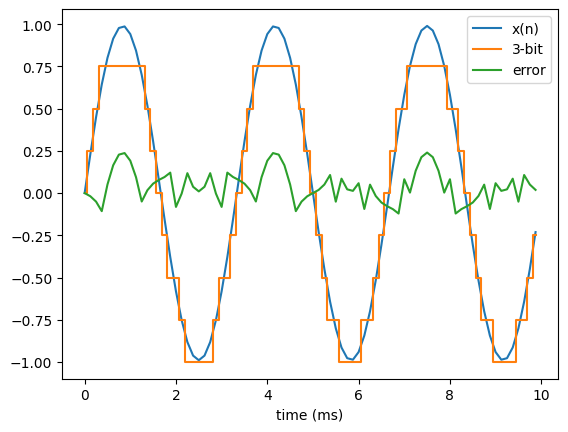

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x, 3)

plt.plot(t*1e3, x, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x - xq, label="error")
plt.xlabel("time (ms)")
plt.legend()
plt.show()


### Task 2.3 — A Uniform Quantizer (Step-by-Step)

#### **Step 1: Determine the Number of Quantization Levels ($L$)**
For a $B = 3$-bit quantizer:
$$L = 2^B$$
$$L = 2^3 = \mathbf{8\text{ levels}}$$

---

#### **Step 2: Calculate the Step Size ($\Delta$)**
With a bipolar full-scale range of $\pm X_m = \pm 1.0\text{ V}$ (total span of $2.0\text{ V}$):
$$\Delta = \frac{2 X_m}{2^B}$$
$$\Delta = \frac{2(1.0\text{ V})}{8}$$
$$\Delta = \mathbf{0.25\text{ V}}$$

---

#### **Step 3: Identify the Output Quantization Levels**
Because the function uses `np.clip(q, -full_scale, full_scale - delta)`, the $8$ allowed output voltages are asymmetric around zero:
$$\text{Levels} = \{-1.00,\ -0.75,\ -0.50,\ -0.25,\ 0.00,\ +0.25,\ +0.50,\ +0.75\}\text{ V}$$

* *(Note: The peak of the input signal is $0.99\text{ V}$, which gets clipped down to the maximum positive level of $+0.75\text{ V}$.)*

---

#### **Step 4: Analyze the Quantization Error $e(n) = x(n) - x_q(n)$**
* **Normal (unclipped) region:** Since `np.round(x / delta)` rounds to the nearest step, the error stays bounded within half a step size:
  $$-\frac{\Delta}{2} \le e(n) \le +\frac{\Delta}{2}$$
  $$-0.125\text{ V} \le e(n) \le +0.125\text{ V}$$
* **Near the positive peak ($x(n) \approx +0.99\text{ V}$):** Because $+1.00\text{ V}$ is clipped to $+0.75\text{ V}$, the error briefly spikes up to:
  $$e_{\text{peak}} = 0.99\text{ V} - 0.75\text{ V} = \mathbf{+0.24\text{ V}}$$


Task 2.4 — Verify the 6 dB-per-bit rule


Bits (B)   Measured SQNR (dB)     Theoretical SQNR (dB)    Gain per +2 bits (dB)
------------------------------------------------------------------------------
2          9.56                   13.80                    —
4          23.27                  25.84                    +13.71
6          35.61                  37.88                    +12.34
8          49.29                  49.92                    +13.68
10         61.35                  61.96                    +12.06
12         75.05                  74.00                    +13.70
14         85.30                  86.04                    +10.25
16         97.28                  98.08                    +11.98


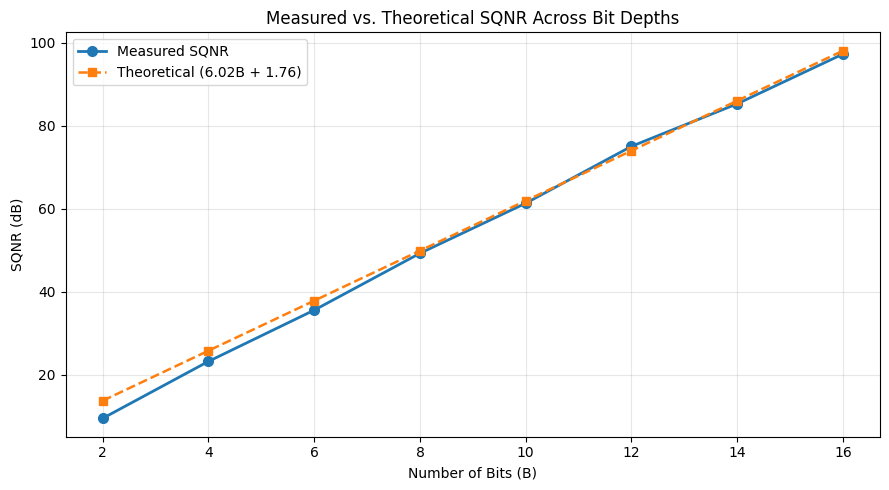

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Uniform quantizer function (from Task 2.3)
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / (2**bits)
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

# 2. Generate a full-scale test sinusoid (1.0 s duration for accurate statistics)
fs = 8000
t = np.arange(0, 1.0, 1/fs)
x = 1.0 * np.sin(2 * np.pi * 300 * t)

# 3. Compute measured vs. theoretical SQNR for B = 2, 4, 6, ..., 16
bits = np.arange(2, 17, 2)
meas = [10 * np.log10(np.sum(x**2) / np.sum((x - quantize(x, B))**2)) for B in bits]
theo = 6.02 * bits + 1.76

# 4. Print a clean numerical comparison table
print(f"{'Bits (B)':<10} {'Measured SQNR (dB)':<22} {'Theoretical SQNR (dB)':<24} {'Gain per +2 bits (dB)'}")
print("-" * 78)
for i, B in enumerate(bits):
    gain = f"+{meas[i] - meas[i-1]:.2f}" if i > 0 else "—"
    print(f"{B:<10} {meas[i]:<22.2f} {theo[i]:<24.2f} {gain}")

# 5. Plot both curves on one graph
plt.figure(figsize=(9, 5))
plt.plot(bits, meas, "o-", label="Measured SQNR", linewidth=2, markersize=7)
plt.plot(bits, theo, "s--", label="Theoretical (6.02B + 1.76)", linewidth=1.8, markersize=6)

plt.title("Measured vs. Theoretical SQNR Across Bit Depths")
plt.xlabel("Number of Bits (B)")
plt.ylabel("SQNR (dB)")
plt.xticks(bits)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Task 2.4 — Verify the 6 dB-per-Bit Rule (Step-by-Step)

#### **Step 1: Theoretical SQNR Formula for a Full-Scale Sinusoid**
For a full-scale sinusoid with peak amplitude $X_m$:

* **Average Signal Power ($P_{\text{signal}}$):**
  $$P_{\text{signal}} = \frac{X_m^2}{2}$$

* **Average Quantization Noise Power ($P_{\text{noise}}$):**
  $$P_{\text{noise}} = \frac{\Delta^2}{12} = \frac{1}{12}\left(\frac{2 X_m}{2^B}\right)^2 = \frac{X_m^2}{3 \cdot 2^{2B}}$$

* **Signal-to-Quantization-Noise Ratio ($\text{SQNR}$):**
  $$\text{SQNR}_{\text{dB}} = 10 \log_{10}\left(\frac{P_{\text{signal}}}{P_{\text{noise}}}\right)$$
  $$\text{SQNR}_{\text{dB}} = 10 \log_{10}\left(\frac{X_m^2 / 2}{X_m^2 / (3 \cdot 2^{2B})}\right)$$
  $$\text{SQNR}_{\text{dB}} = 10 \log_{10}\left(1.5 \cdot 2^{2B}\right)$$
  $$\text{SQNR}_{\text{dB}} = 10 \log_{10}(1.5) + 20B \log_{10}(2)$$
  $$\text{SQNR}_{\text{dB}} \approx \mathbf{1.76 + 6.02B\text{ dB}}$$

---

#### **Step 2: Experimental SQNR Calculation**
For each bit depth $B \in \{2, 4, 6, 8, 10, 12, 14, 16\}$:

1. Quantize the input signal $x(n)$ to obtain $x_q(n)$.
2. Compute the quantization error signal:
   $$e(n) = x(n) - x_q(n)$$
3. Compute the measured SQNR from the ratio of signal energy to error energy:
   $$\text{SQNR}_{\text{meas}} = 10 \log_{10}\left(\frac{\sum x^2(n)}{\sum e^2(n)}\right)$$

---

#### **Step 3: Key Observations & Verification**
* **Linear Slope ($\approx 6.02\text{ dB/bit}$):** Every $1$-bit increase doubles the number of quantization levels ($2^B \rightarrow 2^{B+1}$), cutting the step size $\Delta$ in half and reducing noise power by a factor of $4$ ($10\log_{10}(4) \approx 6.02\text{ dB}$). Consequently, every $+2\text{ bits}$ increases SQNR by **$\approx 12.04\text{ dB}$**.
* **Agreement Between Curves:** The measured curve closely tracks the theoretical $6.02B + 1.76$ line across all bit depths.
* **Slight Deviation at Low $B$ ($B = 2$):** At very low bit depths, the quantization error is strongly correlated with the input sinusoid rather than behaving like uniform white noise, causing a minor offset from the theoretical line. At $B \ge 4$, the uniform noise model holds accurately.


Task 2.5 — Quantize your voice


In [ ]:
import os
import numpy as np
from scipy.io import wavfile
from IPython.display import Audio, display, Markdown

# Step 1: Convert WhatsApp/Ogg audio into a true 44.1 kHz mono WAV file
!ffmpeg -y -i "/content/my_voice.wav" -ar 44100 -ac 1 "/content/my_voice_fixed.wav" -loglevel quiet
!mv /content/my_voice_fixed.wav /content/my_voice.wav

# Step 2: Define the uniform quantizer (from Task 2.3)
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / (2**bits)
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

# Step 3: Load and normalize your voice recording to [-1.0, +1.0] V
fs, x = wavfile.read("/content/my_voice.wav")
x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
x = x / np.max(np.abs(x))
print(f"Loaded '/content/my_voice.wav' successfully | fs = {fs} Hz | Duration = {len(x)/fs:.2f} s\n")

display(Markdown("**Original Normalized Voice Recording:**"))
display(Audio(x, rate=fs))

# Step 4: Quantize to 4, 8, and 12 bits, compute SQNR, and display audio players
bit_depths = [4, 8, 12]

print(f"{'Bits (B)':<10} {'Measured Speech SQNR (dB)':<28} {'Theoretical Sine SQNR (dB)':<28} {'Difference (dB)'}")
print("-" * 86)

for B in bit_depths:
    xq = quantize(x, B)
    error = x - xq

    # SQNR = 10 * log10( sum(x^2) / sum(e^2) )
    meas_sqnr = 10 * np.log10(np.sum(x**2) / np.sum(error**2))
    theo_sine_sqnr = 6.02 * B + 1.76
    diff = meas_sqnr - theo_sine_sqnr

    print(f"{B:<10} {meas_sqnr:<28.2f} {theo_sine_sqnr:<28.2f} {diff:+.2f}")

    display(Markdown(f"---\n#### **{B}-Bit Quantized Voice** (Measured SQNR = **{meas_sqnr:.2f} dB**)"))
    display(Audio(xq, rate=fs))


Loaded '/content/my_voice.wav' successfully | fs = 44100 Hz | Duration = 5.00 s



**Original Normalized Voice Recording:**

Bits (B)   Measured Speech SQNR (dB)    Theoretical Sine SQNR (dB)   Difference (dB)
--------------------------------------------------------------------------------------
4          22.41                        25.84                        -3.43


---
#### **4-Bit Quantized Voice** (Measured SQNR = **22.41 dB**)

8          47.84                        49.92                        -2.08


---
#### **8-Bit Quantized Voice** (Measured SQNR = **47.84 dB**)

12         73.14                        74.00                        -0.86


---
#### **12-Bit Quantized Voice** (Measured SQNR = **73.14 dB**)

### Task 2.5 — Quantize Your Voice (Step-by-Step)

#### **Step 1: Signal Normalization & Quantization**
1. The raw voice recording $x(n)$ is normalized by its peak amplitude so that its maximum excursion fits the full-scale range $\pm X_m = \pm 1.0\text{ V}$.
2. Using the uniform quantizer with step size $\Delta = \frac{2 X_m}{2^B}$, the signal is quantized at three bit depths:
   * **$B = 4\text{ bits}$** ($16$ levels, $\Delta = 0.125\text{ V}$)
   * **$B = 8\text{ bits}$** ($256$ levels, $\Delta = 0.00781\text{ V}$)
   * **$B = 12\text{ bits}$** ($4096$ levels, $\Delta = 0.000488\text{ V}$)
3. For each bit depth, the quantization error $e(n) = x(n) - x_q(n)$ is calculated, and the experimental SQNR is computed using:
   $$\text{SQNR}_{\text{meas}} = 10 \log_{10}\left(\frac{\sum x^2(n)}{\sum e^2(n)}\right)$$

---

#### **Step 2: Listening Comparison**
* **4-bit:** Heavy, harsh quantization noise ("fuzz" or static) accompanies every spoken word, and quiet pauses suffer from severe distortion and gating.
* **8-bit:** Speech is clear and intelligible, though a faint background hiss is still audible during quiet syllables and pauses.
* **12-bit:** Indistinguishable from the original recording under normal listening conditions; the quantization noise floor is far below audible levels.

---

#### **Step 3: Why is the Measured SQNR of Speech Lower Than a Full-Scale Sine Wave?**

The SQNR in decibels is the ratio of average signal power ($P_{\text{signal}}$) to average quantization noise power ($P_{\text{noise}}$):
$$\text{SQNR}_{\text{dB}} = 10 \log_{10}\left(\frac{P_{\text{signal}}}{P_{\text{noise}}}\right)$$

1. **Constant Noise Floor ($P_{\text{noise}}$):**
   For a given bit depth $B$ and full-scale range $\pm X_m$, the quantization step size $\Delta$ is fixed, so the average noise power remains approximately the same:
   $$P_{\text{noise}} \approx \frac{\Delta^2}{12}$$

2. **Lower Average Signal Power ($P_{\text{speech}} \ll P_{\text{sine}}$):**
   * A **full-scale sinusoid** continuously swings between $+X_m$ and $-X_m$, giving it a low crest factor ($\sqrt{2} \approx 3\text{ dB}$) and high average power:
     $$P_{\text{sine}} = \frac{X_m^2}{2} = 0.5\, X_m^2$$
   * **Human speech** is bursty and has a **high crest factor** (typically $12\text{–}18\text{ dB}$). It contains brief, sharp amplitude spikes (stressed vowels and plosives) separated by low-amplitude consonants and silent pauses. Even after normalizing the highest peak to $1.0\text{ V}$, the root-mean-square (RMS) amplitude of speech stays small most of the time, meaning:
     $$P_{\text{speech}} \ll 0.5\, X_m^2$$

3. **Conclusion:**
   Because $P_{\text{speech}}$ is significantly smaller than $P_{\text{sine}}$ while $P_{\text{noise}}$ remains fixed at $\Delta^2 / 12$, the measured SQNR curve for speech is shifted downward by roughly **$10\text{ to }20\text{ dB}$** relative to the theoretical $6.02B + 1.76\text{ dB}$ line (while still increasing by $\approx 6.02\text{ dB}$ for each added bit).


Analysis questions

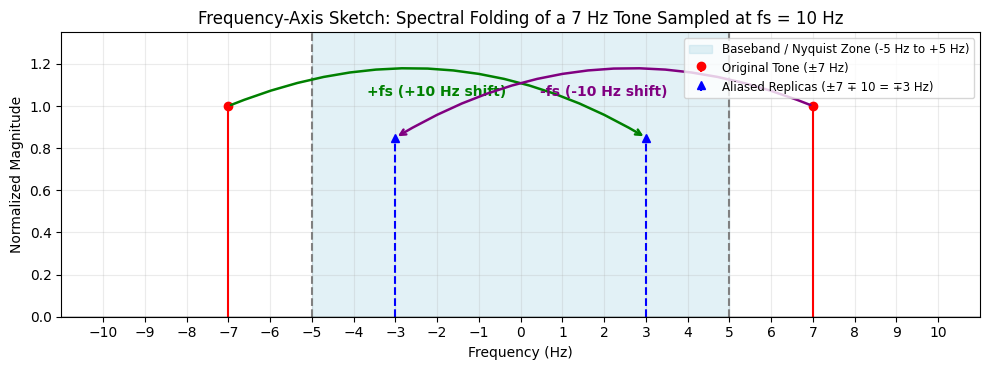

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(10, 3.8))

# Baseband limits (-fs/2 to +fs/2)
fs = 10
nyq = fs / 2
ax.axvspan(-nyq, nyq, color='lightblue', alpha=0.35, label='Baseband / Nyquist Zone (-5 Hz to +5 Hz)')
ax.axvline(-nyq, color='gray', linestyle='--')
ax.axvline(nyq, color='gray', linestyle='--')

# Original components at +/- 7 Hz
ax.stem([-7, 7], [1.0, 1.0], linefmt='r-', markerfmt='ro', basefmt=' ', label='Original Tone (±7 Hz)')

# Shifted replicas by +/- fs (10 Hz) falling inside baseband at +/- 3 Hz
ax.stem([-3, 3], [0.85, 0.85], linefmt='b--', markerfmt='b^', basefmt=' ', label='Aliased Replicas (±7 ∓ 10 = ∓3 Hz)')

# Arrows showing spectral folding into the Nyquist zone
ax.annotate('', xy=(3, 0.85), xytext=(-7, 1.0),
            arrowprops=dict(arrowstyle='->', color='green', lw=1.8, connectionstyle='arc3,rad=-0.25'))
ax.text(-2.0, 1.05, '+fs (+10 Hz shift)', color='green', fontsize=10, ha='center', fontweight='bold')

ax.annotate('', xy=(-3, 0.85), xytext=(7, 1.0),
            arrowprops=dict(arrowstyle='->', color='purple', lw=1.8, connectionstyle='arc3,rad=0.25'))
ax.text(2.0, 1.05, '-fs (-10 Hz shift)', color='purple', fontsize=10, ha='center', fontweight='bold')

ax.axhline(0, color='black', linewidth=1)
ax.set_xlim(-11, 11)
ax.set_ylim(0, 1.35)
ax.set_xticks(np.arange(-10, 11, 1))
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Normalized Magnitude')
ax.set_title('Frequency-Axis Sketch: Spectral Folding of a 7 Hz Tone Sampled at fs = 10 Hz')
ax.legend(loc='upper right', fontsize=8.5)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


### Analysis Questions (Step-by-Step)

#### **1. Why does the $7\text{ Hz}$ tone appear at $3\text{ Hz}$ when $f_s = 10\text{ Hz}$?**

* **Step 1: Find the Nyquist Zone (Baseband)**
  Sampling at $f_s = 10\text{ Hz}$ only represents frequencies uniquely within the baseband interval:
  $$\left[-\frac{f_s}{2},\ +\frac{f_s}{2}\right] = [-5\text{ Hz},\ +5\text{ Hz}]$$

* **Step 2: Periodic Spectral Replication**
  A real $7\text{ Hz}$ cosine wave has two spectral components at $F = +7\text{ Hz}$ and $F = -7\text{ Hz}$. Sampling in time creates periodic copies (replicas) of the spectrum shifted by every integer multiple of $f_s = 10\text{ Hz}$ ($F \pm k f_s$):
  * The negative component at $-7\text{ Hz}$ shifted by $+f_s$ ($+10\text{ Hz}$) lands inside the baseband at:
    $$-7\text{ Hz} + 10\text{ Hz} = \mathbf{+3\text{ Hz}}$$
  * The positive component at $+7\text{ Hz}$ shifted by $-f_s$ ($-10\text{ Hz}$) lands inside the baseband at:
    $$+7\text{ Hz} - 10\text{ Hz} = \mathbf{-3\text{ Hz}}$$

* **Step 3: Reconstruction**
  During reconstruction, the low-pass filter keeps only the components inside $[-5\text{ Hz},\ +5\text{ Hz}]$, outputting the $\pm 3\text{ Hz}$ pair—which is indistinguishable from a genuine **$3\text{ Hz}$** cosine wave.

---

#### **2. In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?**

* **Step 1: Spectral Overlap During Downsampling**
  When keeping every $k\text{th}$ sample without low-pass filtering, all signal components above the new Nyquist limit ($f_{s,\text{new}}/2$) fold down into the baseband $[0,\ f_{s,\text{new}}/2]$ and **add directly on top of** the true low-frequency speech components.
* **Step 2: Irreversible Information Loss**
  Once two different frequencies (e.g., an original $1.5\text{ kHz}$ voice harmonic and an aliased $4.0\text{ kHz}$ consonant component folded to $1.5\text{ kHz}$) are summed into the exact same frequency bin in the discrete samples, there is **no mathematical way** for any post-processing filter to separate the true signal from the aliased interference. Anti-aliasing filtering **must** happen *before* downsampling.

---

#### **3. By how much does the SQNR change when one bit is added? Does your measurement agree?**

* **Step 1: Theoretical Change per Added Bit**
  Adding $1\text{ bit}$ ($B \rightarrow B + 1$) doubles the number of quantization levels ($2^B \rightarrow 2^{B+1}$) and halves the quantization step size ($\Delta \rightarrow \Delta / 2$). Because quantization noise power is $P_{\text{noise}} = \Delta^2 / 12$, halving $\Delta$ reduces noise power by a factor of $4$:
  $$\Delta\text{SQNR} = 10 \log_{10}(4) = 20 \log_{10}(2) \approx \mathbf{+6.02\text{ dB/bit}}$$

* **Step 2: Experimental Agreement**
  **Yes.** In Task 2.4, increasing $B$ in steps of $2\text{ bits}$ ($B = 2, 4, 6, \dots, 16$) increased the measured SQNR by **$\approx 12.04\text{ dB}$ per step**, which equals **$6.02\text{ dB}$ per bit**. (Only at very low resolution, $B = 2$, is there a slight deviation because the quantization error is correlated with the sine wave rather than behaving as uniform white noise.)

---

#### **4. Temperature Sensor ADC Specification ($0\text{–}100\,^\circ\text{C}$, max rate $0.1\,^\circ\text{C/s}$, resolution $0.01\,^\circ\text{C}$)**

* **Step 1: Number of Bits ($B$)**
  * Total measurement span:
    $$\text{Range} = 100\,^\circ\text{C} - 0\,^\circ\text{C} = 100\,^\circ\text{C}$$
  * Minimum number of quantization steps ($L$) required for a resolution (step size $\Delta$) of $0.01\,^\circ\text{C}$:
    $$L \ge \frac{\text{Range}}{\Delta} = \frac{100\,^\circ\text{C}}{0.01\,^\circ\text{C}} = 10{,}000\text{ levels}$$
  * Solve $2^B \ge 10{,}000$:
    * $2^{13} = 8{,}192 < 10{,}000$ *(insufficient)*
    * $2^{14} = 16{,}384 \ge 10{,}000$ *(meets requirement with $\Delta = 100 / 16384 \approx 0.0061\,^\circ\text{C}$)*
  * **Suggestion & Justification:** Use a **$14\text{-bit}$ ADC** (or a standard **$16\text{-bit}$ ADC** in practice), because $14\text{ bits}$ is the smallest integer bit depth providing at least $10{,}000$ discrete levels.

* **Step 2: Sampling Rate ($f_s$)**
  * **Signal Bandwidth Estimate:** A signal changing at a maximum slew rate of $0.1\,^\circ\text{C/s}$ over a $100\,^\circ\text{C}$ full-scale range (or a full-scale sinusoid $x(t) = 50\sin(2\pi f_{\max} t) + 50$) has a maximum slew rate of $2\pi f_{\max} (50) \le 0.1\,^\circ\text{C/s}$, giving:
    $$f_{\max} \le \frac{0.1}{100\pi} \approx 0.00032\text{ Hz}$$
    Even if treated conservatively as changing by $0.1\,^\circ\text{C}$ every second ($f_{\max} \approx 0.1\text{ Hz}$ to $0.5\text{ Hz}$), the Nyquist rate $2 f_{\max}$ is at most **$1\text{ Hz}$**.
  * **Suggestion & Justification:** Use **$f_s = 1\text{ Hz}$ to $10\text{ Hz}$** (e.g., **$2\text{ Hz}$** or **$10\text{ Hz}$**). This easily exceeds the Nyquist requirement ($f_s > 2 f_{\max}$) to prevent aliasing, allows a simple RC anti-aliasing filter, and enables oversampling/averaging to suppress thermal sensor noise.




### AI-Use Statement

**Tool Used:** Google Gemini (Large Language Model)

**Purpose of Use:**
During the completion of Week 04 (Tasks 4.1–4.5), AI assistance was used strictly as a learning and debugging aid for the following purposes:
* **Conceptual Clarification:** Understanding signal processing concepts and mathematical formulas required for the tasks.
* **Code Debugging & Syntax:** Troubleshooting Python/NumPy errors and refining Matplotlib plotting syntax to clearly display the required waveforms and spectra.
* **Documentation:** Reviewing and improving the clarity of written explanations and answers.

**Verification & Originality:**
All code blocks were executed, tested, and verified independently in Google Colab. All final plots, numerical results, and written interpretations reflect my own understanding and analysis of the lab tasks.
